# Реализация полносвязной нейронной сети и сравнение с PyTorch

## 1. Введение  
Целью данной работы является разработка программного инструмента, позволяющего пользователю самостоятельно задавать архитектуру полносвязной нейронной сети, используя для этого простой и гибкий программный интерфейс.  
  
В процессе работы с фреймворком PyTorch у меня возникла идея упростить процесс создания и настройки нейронных сетей, автоматизировав некоторые операции. В рамках данного проекта я решил реализовать собственный подход к построению MLP, который позволил бы сделать процесс построения модели более удобным и интуитивно понятным.  
  
Помимо практической цели, проект также представляет собой попытку разобраться во внутренних механизмах построения и обучения нейронных сетей, реализовав основные компоненты самостоятельно.  

## 2. Основные принципы построения модели в данной реализации    
При разработке инструмента одной из главных идей была возможность гибкой настройки архитектуры полносвязной нейронной сети (MLP). Пользователю должна быть предоставлена возможность самостоятельно определять структуру сети, задавать количество слоёв, количество нейронов в каждом слое, а также выбирать функцию активации для каждого из них.  
  
Отдельное внимание было уделено упрощению процесса конфигурирования модели. В отличие от стандартного подхода в PyTorch, при котором необходимо явно задавать размерности входных и выходных данных для каждого полносвязного слоя, в моей реализации **эти операции выполняются автоматически**.  
  
При создании слоя пользователю достаточно указать желаемое количество нейронов и функцию активации. После определения архитектуры входные данные передаются модели, которая самостоятельно определяет количество входных признаков и рассчитывает необходимые размерности для последующих слоёв, исходя из заданной структуры сети.  
  
Кроме того, автоматизирован процесс формирования связей между слоями. Поскольку каждый нейрон предыдущего слоя связан с каждым нейроном следующего, для представления этих связей используются матрицы весов. Программа самостоятельно определяет размерность каждой такой матрицы на основе количества нейронов в соседних слоях и инициализирует её начальными значениями. Таким образом, пользователю не требуется вручную создавать матрицы весов или определять их размерности.  

Также стоит отметить, что пользователь может самостоятельно выбрать функцию потерь и настроить необходимые гиперпараметры обучения.  
  
Таким образом, основная идея реализации заключается в предоставлении пользователю простого интерфейса для создания и настройки MLP, при котором он самостоятельно определяет архитектуру и основные параметры модели, не тратя время на ручное согласование размерностей отдельных слоёв и другие вспомогательные операции.

## 3. Создание и настройка модели 


Создадим модель полносвязной нейронной сети для распознавания рукописных цифр из набора данных MNIST. Каждое изображение имеет размер 28×28 пикселей и представляется в виде вектора из 784 признаков, значения которых соответствуют интенсивности пикселей. Метки классов представляют собой цифры от 0 до 9. 

Выполним импорт необходимых модулей

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from MLP import *

Подготовим данные для обучения

In [2]:
train_data = np.loadtxt("datasets/mnist_train.csv", delimiter=',', skiprows=1)
test_data = np.loadtxt("datasets/mnist_test.csv", delimiter=',', skiprows=1)
train_data

array([[5., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [4., 0., 0., ..., 0., 0., 0.],
       ...,
       [5., 0., 0., ..., 0., 0., 0.],
       [6., 0., 0., ..., 0., 0., 0.],
       [8., 0., 0., ..., 0., 0., 0.]], shape=(60000, 785))

In [3]:
batch_size = 100

def get_x_y(iteration_numb, data, batch_size):
    beg_idx = batch_size * iteration_numb
    end_idx = beg_idx + batch_size
    batch = data[beg_idx:end_idx]
    y = batch[:, 0].astype(int).reshape(-1, 1)
    x = batch[:, 1:]
    return x, y

In [4]:
x_train, y_train = get_x_y(0, train_data, batch_size)

In [5]:
print(f"Размер батча: {batch_size}")
print(f"Признаки каждого примера батча: {x_train.shape}")
print(f"Метки: {y_train.shape}")

Размер батча: 100
Признаки каждого примера батча: (100, 784)
Метки: (100, 1)


Создадим модель, как объект класса MLP и зададим следующую архитектуру:  
- первый слой содержит 512 нейронов и имеет функцию активации ReLU  
- второй слой содержит 256 нейронов и имеет функцию активации ReLU  
- третий слой содержит 10 нейронов и имеет тождественную функцию активации (Identity)

In [28]:
model = MLP()
model.set_layer(512, "ReLU")
model.set_layer(256, "ReLU")
model.set_layer(10, "Identity")            

Посмотреть текущую архитектуру модели можно с помощью метода *get_settings()*

In [29]:
model.get_settings()

Model is not set!
Layers: 3
0 layer:	512 neurons	Activation func - ReLU
1 layer:	256 neurons	Activation func - ReLU
2 layer:	10 neurons	Activation func - Identity


Для завершения настройки модели необходимо вызвать метод *finish_settings()*, передав ему входные данные. На этом этапе программа определяет количество входных признаков и выполняет инициализацию матриц весов всех слоёв, исходя из заданной архитектуры.

In [30]:
model.finish_settings(x_train) 

Метод *get_weights()* позволяет получить матрицу весов выбранного слоя. Для этого необходимо передать в качестве аргумента индекс интересующего слоя (также, как они описаны при выводе метода *get_settings()*).  
Выведем размеры матрицы весов для каждого из трех слоев.

In [31]:
for i in range(3):
    print(f"Слой: {i} \tРазмер весов: {model.get_weights(i).shape}")

Слой: 0 	Размер весов: (784, 512)
Слой: 1 	Размер весов: (512, 256)
Слой: 2 	Размер весов: (256, 10)


Как можно заметить, размерности матриц весов автоматически определяются на основе количества входных признаков и количества нейронов в соответствующих слоях. Размерность каждой последующей матрицы определяется количеством нейронов предыдущего слоя и текущего слоя. Таким образом, обеспечивается согласованность размерностей при последовательном прохождении данных через сеть.

## 4. Обучение модели

Перед обучением модели требуется указать функцию потерь.  
Для этого необходимо воспользоваться методом *set_loss_function()*, который позволяет задать не только функцию потерь, но и скорость обучения.

In [32]:
lr = 0.001
model.set_loss_function(loss="CrossEntropy", lr=lr)

'CrossEntropy'

Опишем функции для обучения и валидации модели.

In [33]:
min_value = train_data.min()                    # 0
max_value = train_data.max()                    # 255

def train_model(data, batch_size, train_iter, list_of_loss):
    data_length = data.shape[0]
    iterations = int(data_length / batch_size)

    for batch in range(iterations):
        x_train, y_train = get_x_y(batch, data, batch_size)
        x_train = (x_train - min_value) / max_value                     # Нормализуем данные
        predict = model.forward(x_train)
        loss = model.Cross_entropy(y_train, predict)
        if batch % 100 == 0:
            print(f"Batch: {batch}\tLoss: {loss}")

        model.backward(x_train, y_train)
        train_iter += 1
        list_of_loss.append(loss)

    return train_iter

def test_model(data, batch_size):
    data_length = data.shape[0]
    iterations = int(data_length / batch_size)
    loss = 0
    pred_true_elems = 0
    all_elems = 0

    for batch in range(iterations):
        x_test, y_test = get_x_y(batch, data, batch_size)
        x_test = (x_test - min_value) / max_value                           # Нормализуем данные
        predict = model.forward(x_test)
        loss += model.Cross_entropy(y_test, predict)

        proba = model.Softmax(predict)                                      # Преобразовываем логиты в вероятности
        labels = np.argmax(proba, axis=1)                                    # Получаем предсказанное значение
        pred_true_elems += np.sum(labels == y_test.ravel())
        all_elems += y_test.shape[0]

    print(f"Test loss: {loss / iterations}")
    print(f"Accuracy: {pred_true_elems / all_elems}\n")

Теперь можно приступать к обучению модели.

In [34]:
epochs = 13
batch_size = 100

# Для анализа изменения ошибки
train_iter = 0
train_loss = list()

for i in range(epochs):
    print(f"Epoch: {i}")
    train_iter = train_model(train_data, batch_size, train_iter, train_loss)
    test_model(test_data, batch_size)

Epoch: 0
Batch: 0	Loss: 23.679483246168807
Batch: 100	Loss: 9.670857390574332
Batch: 200	Loss: 7.584137627203927
Batch: 300	Loss: 7.7366859124432175
Batch: 400	Loss: 5.270225820483657
Batch: 500	Loss: 4.870357490388278
Test loss: 4.083718481389652
Accuracy: 0.8493

Epoch: 1
Batch: 0	Loss: 2.486882535192879
Batch: 100	Loss: 3.868342956214731
Batch: 200	Loss: 4.9735838008662885
Batch: 300	Loss: 4.974133568352594
Batch: 400	Loss: 3.3157225273725124
Batch: 500	Loss: 3.87707183399784
Test loss: 3.3194059690419455
Accuracy: 0.8767

Epoch: 2
Batch: 0	Loss: 1.934171478114072
Batch: 100	Loss: 3.039391366082804
Batch: 200	Loss: 3.868342142591979
Batch: 300	Loss: 3.979225013869659
Batch: 400	Loss: 1.8539030077385537
Batch: 500	Loss: 3.4264108970876803
Test loss: 2.940625773384799
Accuracy: 0.8904

Epoch: 3
Batch: 0	Loss: 1.6578612669554271
Batch: 100	Loss: 3.039412322751248
Batch: 200	Loss: 3.6485385957751952
Batch: 300	Loss: 3.592051093716858
Batch: 400	Loss: 1.381551055795488
Batch: 500	Loss: 3

Как можно заметить, с каждой эпохой ошибка на тестовой выборке уменьшается, а точность возрастает.  
Следовательно можем сделать вывод о том, что наша модель работает исправно.

Построим график зависимости ошибки предсказания модели для каждой итерации.

Text(0, 0.5, 'Значение ошибки')

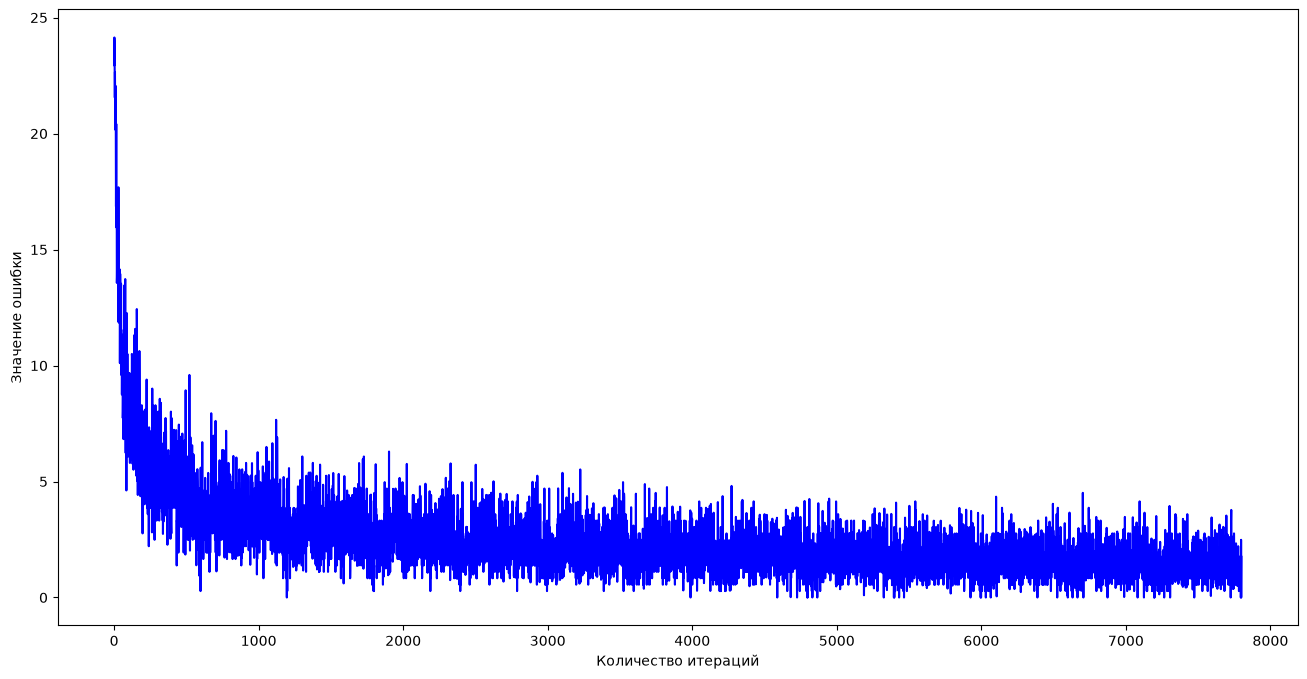

In [50]:
iterations = np.arange(train_iter).tolist()
plt.subplots(figsize=(16, 8))
plt.plot(iterations, train_loss, color="blue")
plt.xlabel("Количество итераций")
plt.ylabel("Значение ошибки")